In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.ticker as ticker

### Libraries Used
| Library | Purpose |
|---|---|
| `pandas` | Data loading, filtering, grouping, aggregation |
| `numpy` | Math operations (log, polyfit for trend lines) |
| `matplotlib` | All chart drawing (bars, scatter, heatmap, dumbbell) |
| `matplotlib.ticker` | Formats axis labels as `$10M`, `${x:,.0f}` etc. |

In [2]:
df = pd.read_csv('Data/movies.csv')
print(df.columns.tolist())

['id', 'title', 'genres', 'original_language', 'overview', 'popularity', 'production_companies', 'release_date', 'budget', 'revenue', 'runtime', 'status', 'tagline', 'vote_average', 'vote_count', 'credits', 'keywords', 'poster_path', 'backdrop_path', 'recommendations']


### 📌 Dataset Loaded
`df.columns.tolist()` prints every column name — gives us a mental map of what data is available before analysis begins.

In [3]:
print(df.describe())

                  id     popularity        budget       revenue       runtime  \
count  769631.000000  769631.000000  7.696310e+05  7.696310e+05  7.285410e+05   
mean   526059.989225       1.857579  3.747597e+05  9.254475e+05  1.921179e+02   
std    250268.796149      15.538170  7.816617e+06  1.926384e+07  8.341890e+04   
min         2.000000       0.600000  0.000000e+00 -1.200000e+01  0.000000e+00   
25%    331134.500000       0.600000  0.000000e+00  0.000000e+00  6.000000e+00   
50%    533455.000000       0.600000  0.000000e+00  0.000000e+00  5.300000e+01   
75%    732659.000000       1.340000  0.000000e+00  0.000000e+00  9.000000e+01   
max    968161.000000    3669.153000  5.000000e+09  2.847246e+09  5.050505e+07   

        vote_average     vote_count  
count  769631.000000  769631.000000  
mean        2.519270      25.794712  
std         3.187398     349.218101  
min         0.000000       0.000000  
25%         0.000000       0.000000  
50%         0.000000       0.000000  
75% 

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 769631 entries, 0 to 769630
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    769631 non-null  int64  
 1   title                 769625 non-null  str    
 2   genres                541313 non-null  str    
 3   original_language     769631 non-null  str    
 4   overview              643998 non-null  str    
 5   popularity            769631 non-null  float64
 6   production_companies  358329 non-null  str    
 7   release_date          707935 non-null  str    
 8   budget                769631 non-null  float64
 9   revenue               769631 non-null  float64
 10  runtime               728541 non-null  float64
 11  status                769631 non-null  str    
 12  tagline               114145 non-null  str    
 13  vote_average          769631 non-null  float64
 14  vote_count            769631 non-null  float64
 15  credits    

###  Data Types & Missing Values
`df.info()` shows:
- Which columns have missing values (`Non-Null Count` < total rows)
- Data types — `object` = text, needs special handling for splitting/exploding

In [5]:
print(df.duplicated().sum())


235


### 📌 Duplicate Check
`df.duplicated().sum()` counts rows where EVERY column is identical.
Duplicates would double-count movies in revenue totals and distort averages.

In [6]:
df_base = df.drop_duplicates(subset=['id']).copy()
df_base = df_base[df_base['status'] == 'Released']

df_base['release_date'] = pd.to_datetime(df_base['release_date'], errors='coerce')
df_base['release_year'] = df_base['release_date'].dt.year

df_money = df_base[(df_base['budget'] > 1000) & (df_base['revenue'] > 1000)].copy()
df_rated = df_base[df_base['vote_count'] >= 100].copy()

print(f"Total Released (df_base): {len(df_base):,}")
print(f"Box Office Slice (df_money): {len(df_money):,}")
print(f"Reliable Ratings Slice (df_rated): {len(df_rated):,}")

Total Released (df_base): 654,258
Box Office Slice (df_money): 9,214
Reliable Ratings Slice (df_rated): 15,545


### 📌 Three Analytical Sub-Datasets Created

```
df       → raw, everything including unreleased films
df_base  → only Released movies, no duplicates (anchor for counts & trends)
df_money → df_base filtered to budget > $1k AND revenue > $1k
           (removes movies where financial data is missing/zero)
df_rated → df_base filtered to vote_count >= 100
           (removes movies with too few votes to trust the rating)
```

**Why split into three?**
Using raw `df` for financial analysis would include movies with `budget = 0` (data not available), which would completely wreck averages and correlations. Each sub-dataset answers a different type of question cleanly.

In [7]:
yearly = (
    df_base[(df_base['release_year'] >= 1920) & (df_base['release_year'] <= 2025)]
    .groupby('release_year')
    .agg(
        movie_count=('id', 'count'),
        median_runtime=('runtime', lambda s: s[(s > 0) & (s <= 300)].median())
    )
    .reset_index()
)

# Global Production Trends

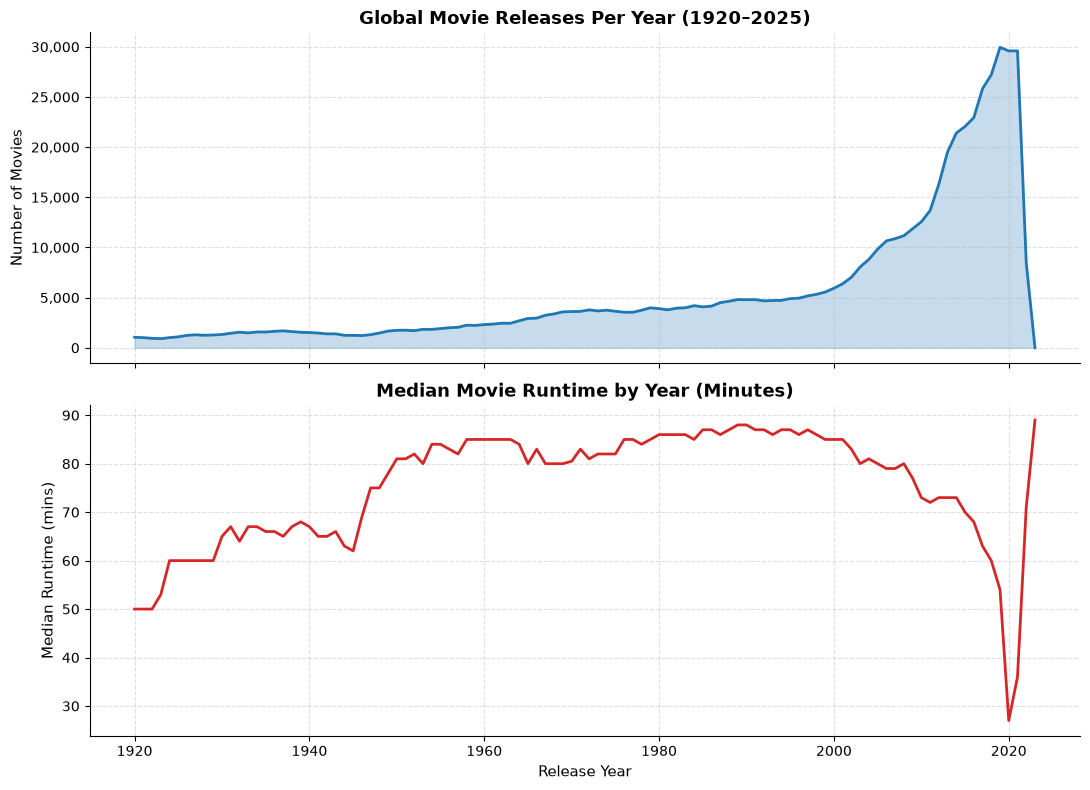

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# Top Panel: Area chart of Global Movie Releases
ax1.plot(yearly['release_year'], yearly['movie_count'], color='#1f77b4', linewidth=2)
ax1.fill_between(yearly['release_year'], yearly['movie_count'], color='#1f77b4', alpha=0.25)
ax1.set_title('Global Movie Releases Per Year (1920–2025)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Number of Movies', fontsize=11)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.grid(True, linestyle='--', alpha=0.4)

# Bottom Panel: Line chart of Median Runtime
ax2.plot(yearly['release_year'], yearly['median_runtime'], color='#d62728', linewidth=2)
ax2.set_title('Median Movie Runtime by Year (Minutes)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Release Year', fontsize=11)
ax2.set_ylabel('Median Runtime (mins)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.4)

# Clean up top/right borders
for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

###  Finding: Global Production Trends (1920–2025)

**Chart 1 — Movie Count (top panel):**
- Film production grew slowly through the mid-20th century
- Explosive growth post-2000 driven by digital filmmaking and streaming platforms
- `fill_between` shades the area under the line — makes volume growth visually obvious

**Chart 2 — Median Runtime (bottom panel):**
- Early films (1920s–1960s) often ran shorter — technology and audience habits were different
- Runtime gradually standardised around 90–110 minutes from the 1980s onward
- `sharex=True` links both charts to the same x-axis so years align perfectly



            id                                        title  \
0       639933                                 The Northman   
0       639933                                 The Northman   
0       639933                                 The Northman   
1       338953  Fantastic Beasts: The Secrets of Dumbledore   
1       338953  Fantastic Beasts: The Secrets of Dumbledore   
...        ...                                          ...   
762691  758257                             The Devil Series   
762869  758253                                Ek Kahani Maa   
762869  758253                                Ek Kahani Maa   
763752  773862                  Your Parents Will Come Back   
768258  778088                    Dan's Humongous Apartment   

                              genres original_language  \
0           Action-Adventure-Fantasy                en   
0           Action-Adventure-Fantasy                en   
0           Action-Adventure-Fantasy                en   
1          

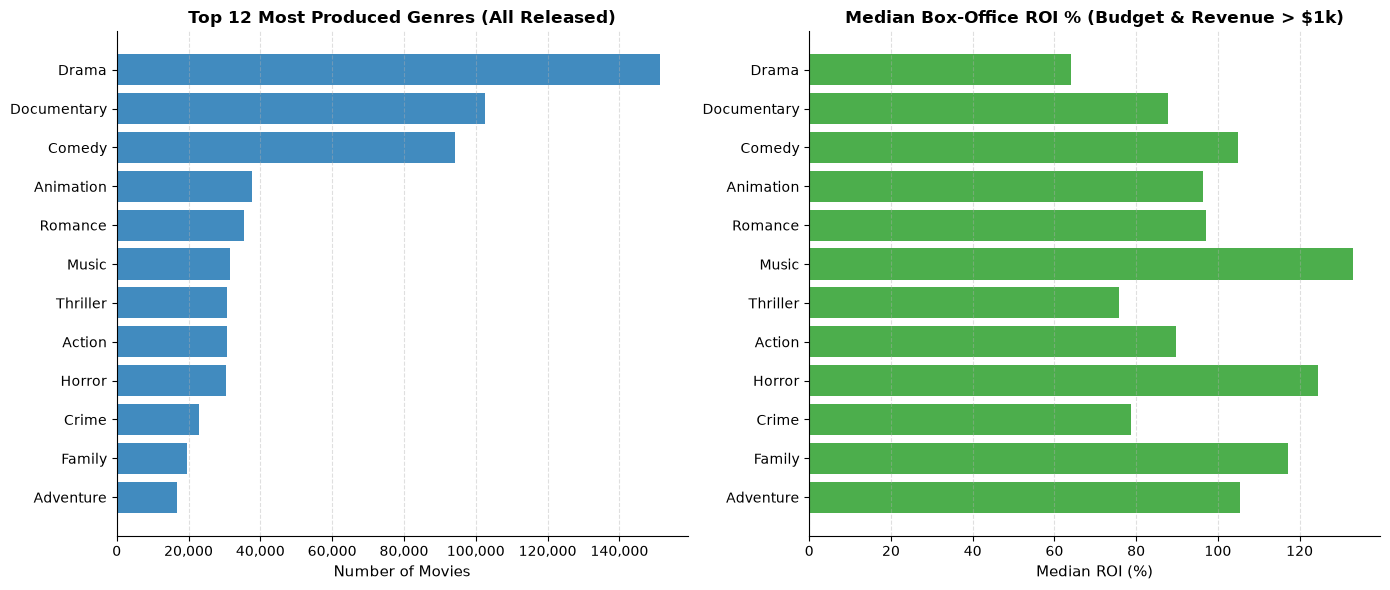

In [9]:

genres_base = df_base.dropna(subset=['genres']).copy()
genres_base['genre'] = genres_base['genres'].str.split(r'\s*[-,]\s*')
exploded_base = genres_base.explode('genre')
exploded_base = exploded_base[exploded_base['genre'] != '']

top_12_counts = exploded_base['genre'].value_counts().head(12).sort_values()

money_genres = df_money.dropna(subset=['genres']).copy()
money_genres['roi_pct'] = ((money_genres['revenue'] - money_genres['budget']) / money_genres['budget']) * 100
money_genres['genre'] = money_genres['genres'].str.split(r'\s*[-,]\s*')
exploded_money = money_genres.explode('genre')
print(exploded_money)

median_roi = (
    exploded_money[exploded_money['genre'].isin(top_12_counts.index)]
    .groupby('genre')['roi_pct']
    .median()
    .reindex(top_12_counts.index)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.barh(top_12_counts.index, top_12_counts.values, color='#1f77b4', alpha=0.85)
ax1.set_title('Top 12 Most Produced Genres (All Released)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Movies', fontsize=11)
ax1.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.grid(axis='x', linestyle='--', alpha=0.4)

ax2.barh(median_roi.index, median_roi.values, color='#2ca02c', alpha=0.85)
ax2.set_title('Median Box-Office ROI % (Budget & Revenue > $1k)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Median ROI (%)', fontsize=11)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


ROI = Return on Investment. 100% ROI means the movie earned double its budget.

### Finding: Genre Volume vs. ROI
The two charts answer different questions:
- **Left** — Which genres are made the most? (Drama, Comedy dominate volume)
- **Right** — Which genres are most profitable per dollar invested? (Horror often has very high ROI — cheap to make, can earn a lot)

A genre being popular doesn't mean it's profitable, and vice versa.

---
##  Studio Analysis — Box Office vs. Audience Ratings

Sample raw values:
 ['New Regency Pictures-Focus Features-Perfect World Pictures-Square Peg', 'Warner Bros. Pictures-Heyday Films', 'Paramount-Fortis Films-3dot Productions-Exhibit A Film']


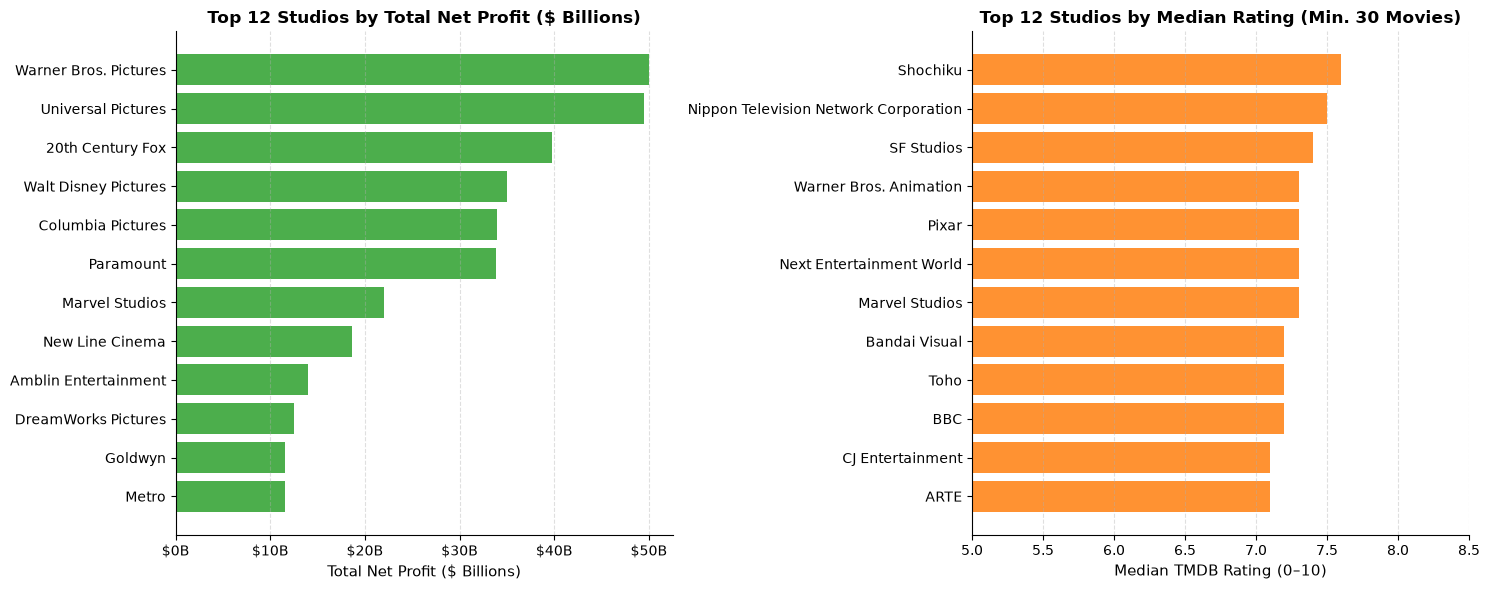

In [10]:
# Quick peek at how studio names are separated in your dataset
print("Sample raw values:\n", df_money['production_companies'].dropna().head(3).tolist())

# --- 1. BOX-OFFICE SUCCESS: TOTAL NET PROFIT (df_money) ---
studios_money = df_money.dropna(subset=['production_companies']).copy()
studios_money['profit_billions'] = (studios_money['revenue'] - studios_money['budget']) / 1e9

# Split by '-' (the standard delimiter in this TMDB dump) and explode into separate rows
studios_money['studio'] = studios_money['production_companies'].str.split('-')
exploded_money_studios = studios_money.explode('studio')
exploded_money_studios['studio'] = exploded_money_studios['studio'].str.strip()
exploded_money_studios = exploded_money_studios[exploded_money_studios['studio'] != '']

top_profit_studios = (
    exploded_money_studios.groupby('studio')['profit_billions']
    .sum()
    .nlargest(12)
    .sort_values()
)

# --- 2. AUDIENCE SUCCESS: MEDIAN RATING OF MAJOR STUDIOS (df_rated) ---
studios_rated = df_rated.dropna(subset=['production_companies']).copy()
studios_rated['studio'] = studios_rated['production_companies'].str.split('-')
exploded_rated_studios = studios_rated.explode('studio')
exploded_rated_studios['studio'] = exploded_rated_studios['studio'].str.strip()
exploded_rated_studios = exploded_rated_studios[exploded_rated_studios['studio'] != '']

studio_ratings = (
    exploded_rated_studios.groupby('studio')
    .agg(
        movie_count=('id', 'count'),
        median_rating=('vote_average', 'median')
    )
)

# Keep only established studios with at least 30 well-voted films
top_rated_studios = (
    studio_ratings[studio_ratings['movie_count'] >= 30]['median_rating']
    .nlargest(12)
    .sort_values()
)

# --- 3. PLOT SIDE-BY-SIDE IN MATPLOTLIB ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left Panel: Total Box-Office Profit ($ Billions)
ax1.barh(top_profit_studios.index, top_profit_studios.values, color='#2ca02c', alpha=0.85)
ax1.set_title('Top 12 Studios by Total Net Profit ($ Billions)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Total Net Profit ($ Billions)', fontsize=11)
ax1.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}B'))
ax1.grid(axis='x', linestyle='--', alpha=0.4)

# Right Panel: Median Audience Rating (Min. 30 Rated Films)
ax2.barh(top_rated_studios.index, top_rated_studios.values, color='#ff7f0e', alpha=0.85)
ax2.set_title('Top 12 Studios by Median Rating (Min. 30 Movies)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Median TMDB Rating (0–10)', fontsize=11)
ax2.set_xlim(5.0, 8.5)  # Zoom in on the 5.0–8.5 range to clearly see differences
ax2.grid(axis='x', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


###  Finding: Studios
- The highest-grossing studios (by total profit) are dominated by major Hollywood houses with franchise movies
- The highest-rated studios tend to be prestige or independent labels focused on quality over volume
- These two lists rarely overlap — financial and critical success are different businesses

---
##  Does Budget Affect Revenue?

Pearson Correlation (Budget vs. Revenue): 0.739


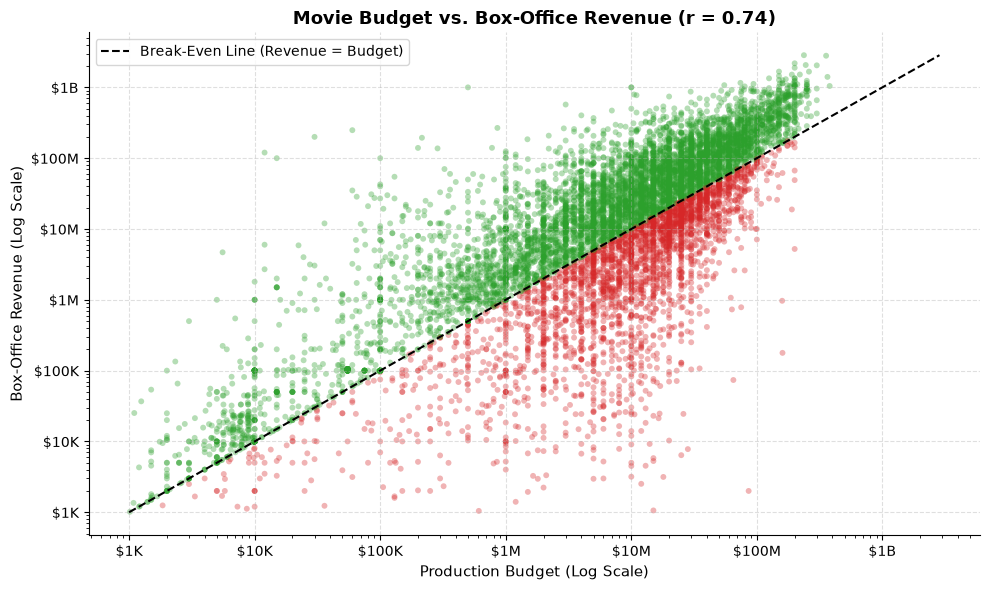

In [11]:
import numpy as np

# 1. Calculate exact correlation in your df_money slice
corr = df_money['budget'].corr(df_money['revenue'])
print(f"Pearson Correlation (Budget vs. Revenue): {corr:.3f}")

# 2. Create a Log-Log Scatter Plot
fig, ax = plt.subplots(figsize=(10, 6))

# Color points green if profitable (revenue > budget), red if they lost money
is_profitable = df_money['revenue'] >= df_money['budget']
colors = np.where(is_profitable, '#2ca02c', '#d62728')

ax.scatter(
    df_money['budget'],
    df_money['revenue'],
    c=colors,
    alpha=0.35,
    edgecolors='none',
    s=18
)

# 3. Draw the Break-Even diagonal line (Revenue == Budget)
min_val = 1_000
max_val = max(df_money['budget'].max(), df_money['revenue'].max())
ax.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=1.5, label='Break-Even Line (Revenue = Budget)')

# 4. Use logarithmic scales so $10k indie films and $300M blockbusters are both visible
ax.set_xscale('log')
ax.set_yscale('log')

# Format axes as clean dollar amounts ($10K, $1M, $100M)
def dollar_formatter(x, pos):
    if x >= 1e9:
        return f'${x/1e9:.0f}B'
    elif x >= 1e6:
        return f'${x/1e6:.0f}M'
    elif x >= 1e3:
        return f'${x/1e3:.0f}K'
    return f'${x:.0f}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(dollar_formatter))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(dollar_formatter))

ax.set_title(f'Movie Budget vs. Box-Office Revenue (r = {corr:.2f})', fontsize=13, fontweight='bold')
ax.set_xlabel('Production Budget (Log Scale)', fontsize=11)
ax.set_ylabel('Box-Office Revenue (Log Scale)', fontsize=11)
ax.legend(loc='upper left')
ax.grid(True, which='major', linestyle='--', alpha=0.4)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Budget vs. Revenue
Higher budgets generally produce higher revenues, but the relationship is not guaranteed.
Many high-budget films fall below the break-even line — spending more does not eliminate risk.

---
##  Does High Rating Mean High Revenue? Does Budget Buy Better Ratings?

Correlation (Rating vs. Revenue): 0.181
Correlation (Budget vs. Rating):  -0.004


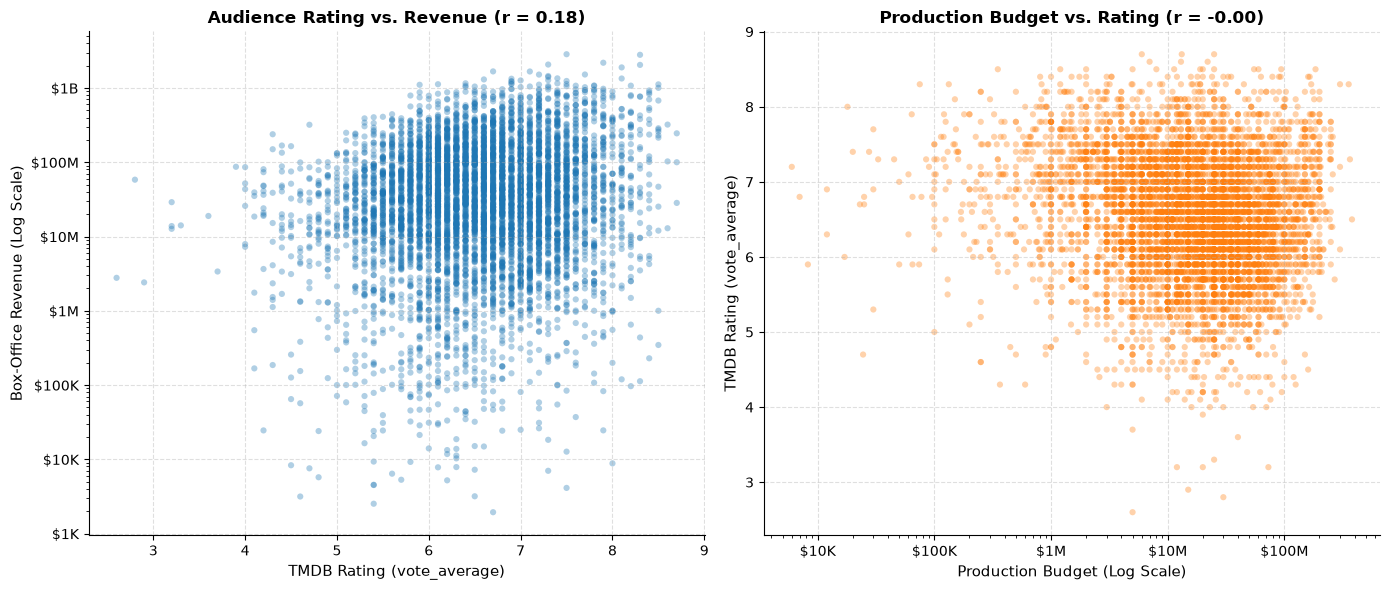

In [13]:
# Combine financial filter (df_money) with reliable vote threshold (>= 100 votes)
df_clean = df_money[df_money['vote_count'] >= 100].copy()

# Calculate exact correlations in your dataset
r_rating_rev = df_clean['vote_average'].corr(df_clean['revenue'])
r_budget_rating = df_clean['budget'].corr(df_clean['vote_average'])

print(f"Correlation (Rating vs. Revenue): {r_rating_rev:.3f}")
print(f"Correlation (Budget vs. Rating):  {r_budget_rating:.3f}")

# Create side-by-side Matplotlib plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left Panel: Does Higher Rating Mean Higher Revenue?
ax1.scatter(df_clean['vote_average'], df_clean['revenue'], alpha=0.35, color='#1f77b4', edgecolors='none', s=20)
ax1.set_yscale('log')
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(dollar_formatter))
ax1.set_title(f'Audience Rating vs. Revenue (r = {r_rating_rev:.2f})', fontsize=12, fontweight='bold')
ax1.set_xlabel('TMDB Rating (vote_average)', fontsize=11)
ax1.set_ylabel('Box-Office Revenue (Log Scale)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.4)

# Right Panel: Do Higher Budgets Get Better Ratings?
ax2.scatter(df_clean['budget'], df_clean['vote_average'], alpha=0.35, color='#ff7f0e', edgecolors='none', s=20)
ax2.set_xscale('log')
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(dollar_formatter))
ax2.set_title(f'Production Budget vs. Rating (r = {r_budget_rating:.2f})', fontsize=12, fontweight='bold')
ax2.set_xlabel('Production Budget (Log Scale)', fontsize=11)
ax2.set_ylabel('TMDB Rating (vote_average)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


###  Finding: Ratings & Money
Critical quality and commercial success are largely independent variables in the film industry.

---
##  Actor Analysis — Box Office Stars vs. Critically Acclaimed Stars

Sample credits: ["Alexander Skarsgård-Nicole Kidman-Claes Bang-Ethan Hawke-Anya Taylor-Joy-Willem Dafoe-Björk-Gustav Lindh-Phill Martin-Eldar Skar-Olwen Fouéré-Oscar Novak-Ingvar Sigurdsson-Jack Walsh-Ian Whyte-Katie Pattinson-Kate Dickie-Edgar Abram-Elliott Rose-Jack Gassmann-Andrea O’Neill-Rebecca Ineson-Ísadóra Bjarkardóttir Barney-Kevin Horsham-Seamus O'Hara-Scott Sinclair-Tadhg Murphy-James Yates-Hafþór Júlíus Björnsson-Ian Gerard Whyte-Ralph Ineson-Murray McArthur-Nille Glæsel-Jonas Lorentzen-Magne Osnes-Ineta Sliuzaite-Finn Lafferty-Jon Campling-Helen Roche-Gareth Parker-Faoileann Cunningham-Mark Fitzgerald-Gavin Peden-Joel Hicks-Chris Finlayson-Eric Higgins-Matt Symonds-Luca Evans-James Harper-Jones-Thomas Harper-Jones-Sheila Fitton-Lily Bird", 'Jude Law-Eddie Redmayne-Mads Mikkelsen-Ezra Miller-Dan Fogler-Alison Sudol-Callum Turner-Jessica Williams-Katherine Waterston-Oliver Masucci-Richard Coyle-William Nadylam-Maria Fernanda Cândido-Poppy Corby-Tuech-Victoria Yeates-Aleksand

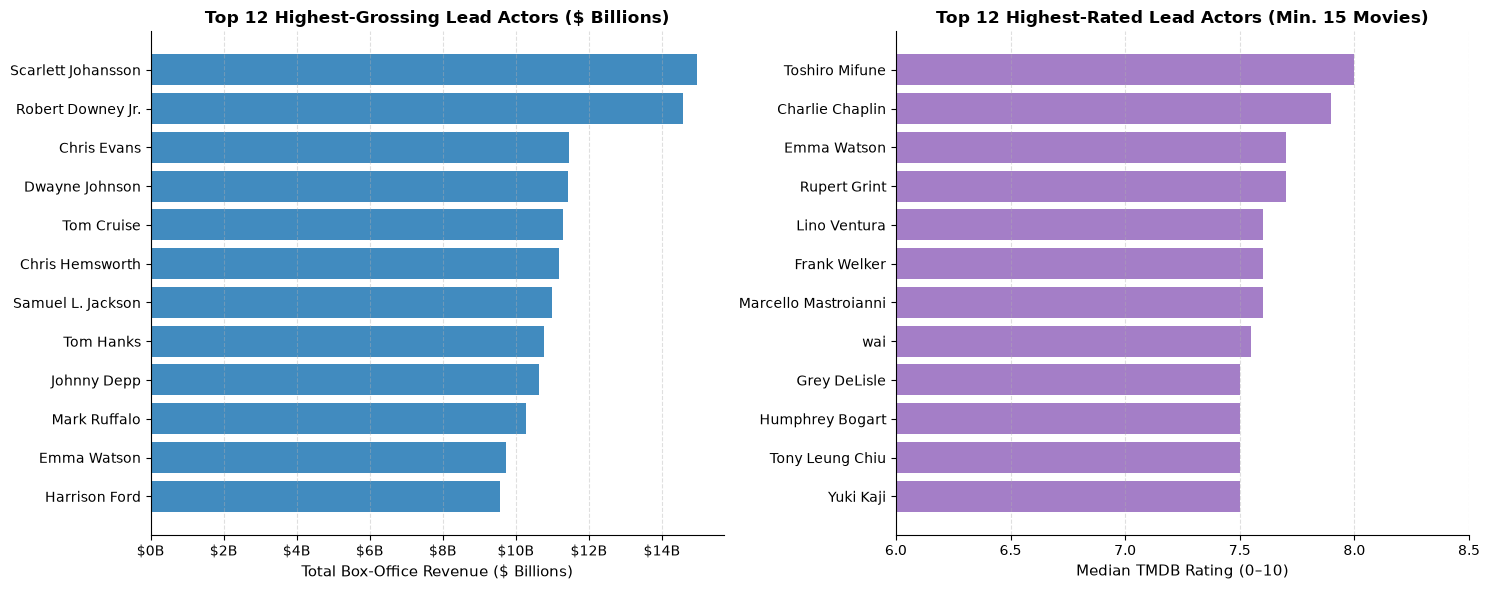

In [14]:
# 1. Verify that 'credits' contains hyphen-separated actor names
print("Sample credits:", df_money['credits'].dropna().head(2).tolist())

# --- 2. HIGHEST-GROSSING STARS (Total Box-Office Revenue in df_money) ---
cast_money = df_money.dropna(subset=['credits']).copy()
cast_money['revenue_billions'] = cast_money['revenue'] / 1e9

# Keep top 5 billed actors per movie so minor extras don't get blockbuster credit
cast_money['actor'] = cast_money['credits'].str.split('-').str[:5]
exploded_money_cast = cast_money.explode('actor')
exploded_money_cast['actor'] = exploded_money_cast['actor'].str.strip()
exploded_money_cast = exploded_money_cast[exploded_money_cast['actor'] != '']

top_grossing_actors = (
    exploded_money_cast.groupby('actor')['revenue_billions']
    .sum()
    .nlargest(12)
    .sort_values()
)

# --- 3. HIGHEST-RATED STARS (Median Rating in df_rated, Min. 15 Movies) ---
cast_rated = df_rated.dropna(subset=['credits']).copy()
cast_rated['actor'] = cast_rated['credits'].str.split('-').str[:5]
exploded_rated_cast = cast_rated.explode('actor')
exploded_rated_cast['actor'] = exploded_rated_cast['actor'].str.strip()
exploded_rated_cast = exploded_rated_cast[exploded_rated_cast['actor'] != '']

actor_ratings = (
    exploded_rated_cast.groupby('actor')
    .agg(
        movie_count=('id', 'count'),
        median_rating=('vote_average', 'median')
    )
)

top_rated_actors = (
    actor_ratings[actor_ratings['movie_count'] >= 15]['median_rating']
    .nlargest(12)
    .sort_values()
)

# --- 4. PLOT SIDE-BY-SIDE IN MATPLOTLIB ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left Panel: Total Box-Office Revenue ($ Billions)
ax1.barh(top_grossing_actors.index, top_grossing_actors.values, color='#1f77b4', alpha=0.85)
ax1.set_title('Top 12 Highest-Grossing Lead Actors ($ Billions)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Total Box-Office Revenue ($ Billions)', fontsize=11)
ax1.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}B'))
ax1.grid(axis='x', linestyle='--', alpha=0.4)

# Right Panel: Median TMDB Rating (Min. 15 Rated Films)
ax2.barh(top_rated_actors.index, top_rated_actors.values, color='#9467bd', alpha=0.85)
ax2.set_title('Top 12 Highest-Rated Lead Actors (Min. 15 Movies)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Median TMDB Rating (0–10)', fontsize=11)
ax2.set_xlim(6.0, 8.5)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Actor Starpower
- The highest-grossing actors are dominated by franchise-film leads (superhero, adventure)
- The highest-rated actors tend to work in prestige dramas and indie films
- Very few names appear on both lists — box-office appeal and critical acclaim rarely coincide

Total financially tracked movies: 9,214
Revenue > Budget (Gross Profitable): 6,225 (67.6%)
Revenue >= 2x Budget (True Theatrical Profit): 4,428 (48.1%)
Revenue <= Budget (Lost Money): 2,989 (32.4%)


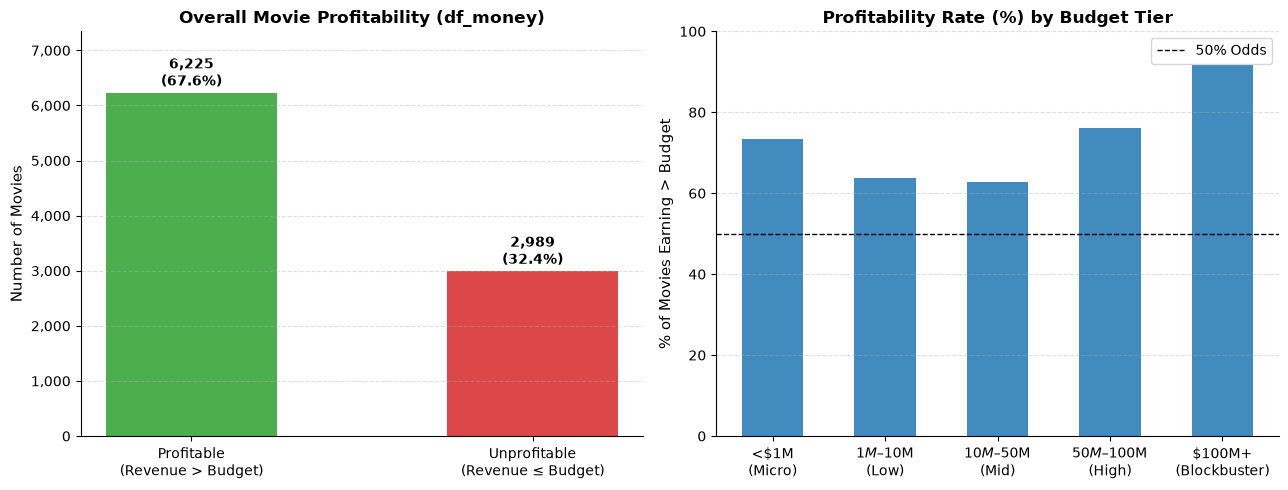

In [15]:
# 1. Exact counts and percentages in df_money
total_tracked = len(df_money)
paper_profitable = (df_money['revenue'] > df_money['budget']).sum()
true_profitable = (df_money['revenue'] >= 2 * df_money['budget']).sum()
unprofitable = total_tracked - paper_profitable

print(f"Total financially tracked movies: {total_tracked:,}")
print(f"Revenue > Budget (Gross Profitable): {paper_profitable:,} ({paper_profitable / total_tracked * 100:.1f}%)")
print(f"Revenue >= 2x Budget (True Theatrical Profit): {true_profitable:,} ({true_profitable / total_tracked * 100:.1f}%)")
print(f"Revenue <= Budget (Lost Money): {unprofitable:,} ({unprofitable / total_tracked * 100:.1f}%)")

# 2. Break down profitability rate by Budget Tier
bins = [1_000, 1_000_000, 10_000_000, 50_000_000, 100_000_000, 1_000_000_000]
labels = ['<$1M\n(Micro)', '$1M–$10M\n(Low)', '$10M–$50M\n(Mid)', '$50M–$100M\n(High)', '$100M+\n(Blockbuster)']

df_money['budget_tier'] = pd.cut(df_money['budget'], bins=bins, labels=labels)
df_money['is_profitable'] = df_money['revenue'] > df_money['budget']

tier_summary = df_money.groupby('budget_tier', observed=False)['is_profitable'].mean() * 100

# 3. Plot Overall Split & Profitability by Budget Tier
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Panel: Overall Profitable vs. Unprofitable Bar Chart
categories = ['Profitable\n(Revenue > Budget)', 'Unprofitable\n(Revenue ≤ Budget)']
counts = [paper_profitable, unprofitable]
bars = ax1.bar(categories, counts, color=['#2ca02c', '#d62728'], width=0.5, alpha=0.85)
ax1.set_title('Overall Movie Profitability (df_money)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Number of Movies', fontsize=11)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Add exact count and percentage labels on top of bars
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + (total_tracked * 0.015),
             f"{h:,}\n({h/total_tracked*100:.1f}%)", ha='center', fontweight='bold', fontsize=10)
ax1.set_ylim(0, max(counts) * 1.18)

# Right Panel: % of Movies Profitable by Budget Size
ax2.bar(tier_summary.index, tier_summary.values, color='#1f77b4', width=0.55, alpha=0.85)
ax2.axhline(50, color='black', linestyle='--', linewidth=1, label='50% Odds')
ax2.set_title('Profitability Rate (%) by Budget Tier', fontsize=12, fontweight='bold')
ax2.set_ylabel('% of Movies Earning > Budget', fontsize=11)
ax2.set_ylim(0, 100)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

###  Finding: Movie Profitability Reality

In Hollywood, studios typically spend 50–100% of the production budget again on marketing. So a film needs roughly **2× its budget** in revenue just to break even in reality.



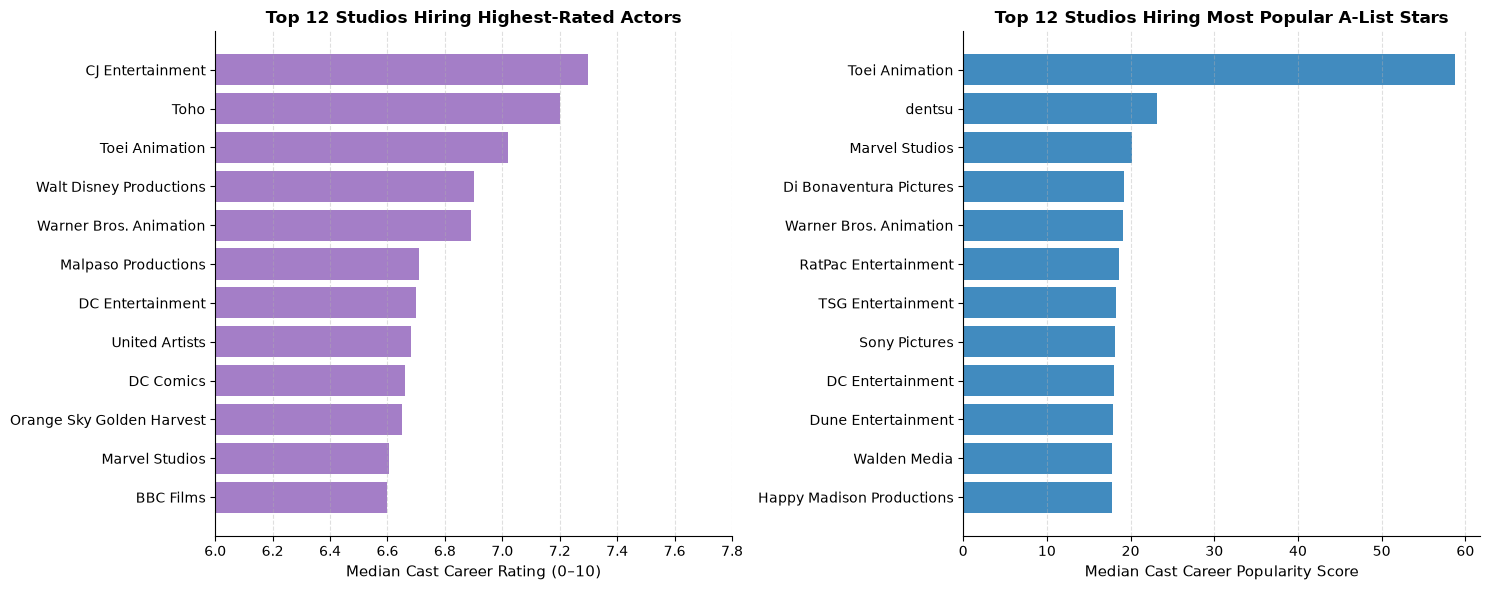

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. PREPARE STUDIO-ACTOR PAIRS FROM df_rated ---
valid = df_rated.dropna(subset=['production_companies', 'credits']).copy()

# Keep top 5 billed actors per movie so minor extras don't dilute studio scores
valid['actor'] = valid['credits'].str.split('-').str[:5]
actors_df = valid[['id', 'vote_average', 'popularity', 'actor']].explode('actor')
actors_df['actor'] = actors_df['actor'].str.strip()
actors_df = actors_df[actors_df['actor'] != '']

# --- 2. COMPUTE EACH ACTOR'S CAREER TRACK RECORD ---
actor_stats = (
    actors_df.groupby('actor')
    .agg(
        films=('id', 'count'),
        career_rating=('vote_average', 'median'),
        career_popularity=('popularity', 'median')
    )
)
# Keep established actors with at least 10 well-voted films
established_actors = actor_stats[actor_stats['films'] >= 10]

# Merge actor career scores back onto each movie's cast
cast_scored = actors_df.merge(
    established_actors[['career_rating', 'career_popularity']],
    on='actor',
    how='inner'
)

# Average cast talent score per movie
movie_cast_scores = cast_scored.groupby('id').agg(
    avg_cast_rating=('career_rating', 'mean'),
    avg_cast_popularity=('career_popularity', 'mean')
)

# --- 3. LINK CAST SCORES TO PRODUCTION COMPANIES ---
studio_movies = valid[['id', 'production_companies']].merge(movie_cast_scores, on='id', how='inner')
studio_movies['studio'] = studio_movies['production_companies'].str.split('-')
exploded_studios = studio_movies.explode('studio')
exploded_studios['studio'] = exploded_studios['studio'].str.strip()
exploded_studios = exploded_studios[exploded_studios['studio'] != '']

studio_talent = (
    exploded_studios.groupby('studio')
    .agg(
        movie_count=('id', 'count'),
        cast_acclaim_score=('avg_cast_rating', 'median'),
        cast_starpower_score=('avg_cast_popularity', 'median')
    )
)

# Filter to established studios with at least 30 rated movies
major_studios = studio_talent[studio_talent['movie_count'] >= 30]

top_acclaim_studios = major_studios['cast_acclaim_score'].nlargest(12).sort_values()
top_starpower_studios = major_studios['cast_starpower_score'].nlargest(12).sort_values()

# --- 4. PLOT SIDE-BY-SIDE IN MATPLOTLIB ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left Panel: Studios Hiring the Highest-Rated Actors
ax1.barh(top_acclaim_studios.index, top_acclaim_studios.values, color='#9467bd', alpha=0.85)
ax1.set_title('Top 12 Studios Hiring Highest-Rated Actors', fontsize=12, fontweight='bold')
ax1.set_xlabel('Median Cast Career Rating (0–10)', fontsize=11)
ax1.set_xlim(6.0, 7.8)
ax1.grid(axis='x', linestyle='--', alpha=0.4)

# Right Panel: Studios Hiring the Biggest A-List / Popular Stars
ax2.barh(top_starpower_studios.index, top_starpower_studios.values, color='#1f77b4', alpha=0.85)
ax2.set_title('Top 12 Studios Hiring Most Popular A-List Stars', fontsize=12, fontweight='bold')
ax2.set_xlabel('Median Cast Career Popularity Score', fontsize=11)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


###  Finding: Studio Casting Strategies
Prestige studios (arthouse, awards-focused) hire actors with high career ratings.
Commercial studios hire actors with high popularity scores.
These are different strategies for different markets.

Correlation (Cast Past Rating vs. Movie Rating): 0.457
Correlation (Cast Star Power vs. Movie Rating):  0.039


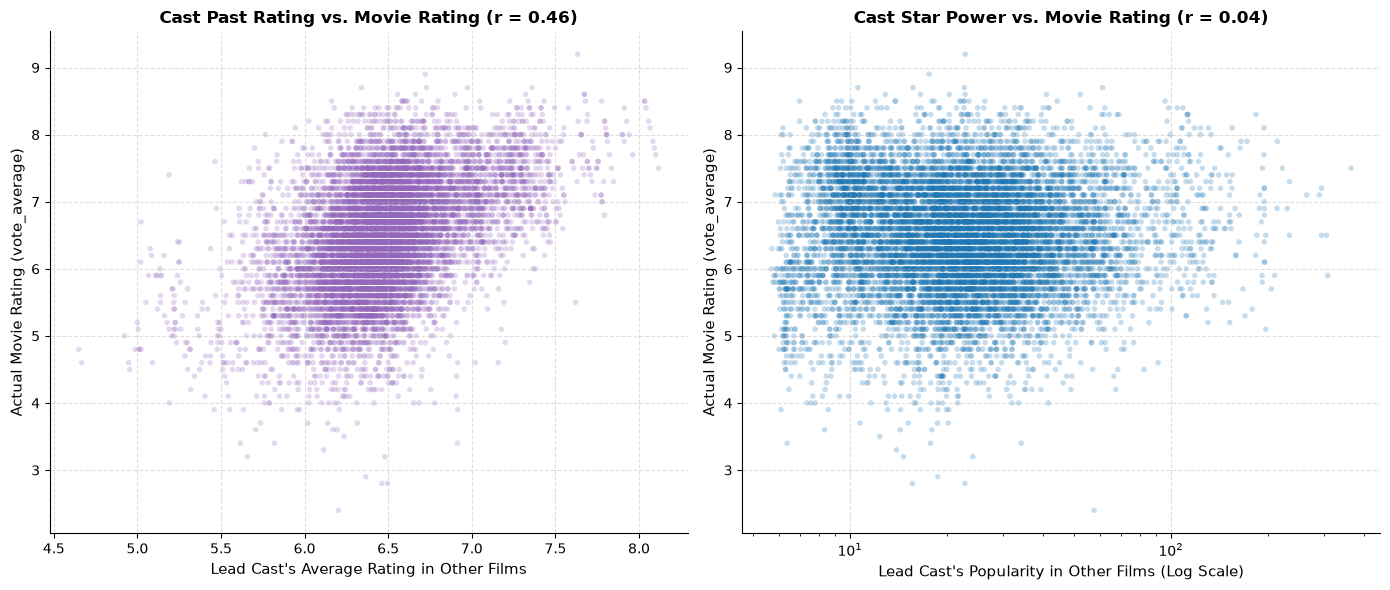

In [17]:
import matplotlib.pyplot as plt

# 1. Start from df_rated (movies with >= 100 votes) and take top 5 billed actors
cast_df = df_rated.dropna(subset=['credits']).copy()
cast_df['actor'] = cast_df['credits'].str.split('-').str[:5]
exploded = cast_df[['id', 'vote_average', 'popularity', 'actor']].explode('actor')
exploded['actor'] = exploded['actor'].str.strip()
exploded = exploded[exploded['actor'] != '']

# 2. Compute each actor's track record on OTHER movies (avoids data leakage)
actor_totals = exploded.groupby('actor').agg(
    films=('id', 'count'),
    sum_rating=('vote_average', 'sum'),
    sum_pop=('popularity', 'sum')
)
actor_totals = actor_totals[actor_totals['films'] >= 10]

merged = exploded.merge(actor_totals, on='actor', how='inner')
merged['other_rating'] = (merged['sum_rating'] - merged['vote_average']) / (merged['films'] - 1)
merged['other_pop'] = (merged['sum_pop'] - merged['popularity']) / (merged['films'] - 1)

# 3. Average the lead cast's scores per movie and compare against actual movie rating
movie_test = (
    merged.groupby('id')
    .agg(
        actual_rating=('vote_average', 'first'),
        cast_prior_rating=('other_rating', 'mean'),
        cast_star_power=('other_pop', 'mean')
    )
)

r_acclaim = movie_test['cast_prior_rating'].corr(movie_test['actual_rating'])
r_starpower = movie_test['cast_star_power'].corr(movie_test['actual_rating'])

print(f"Correlation (Cast Past Rating vs. Movie Rating): {r_acclaim:.3f}")
print(f"Correlation (Cast Star Power vs. Movie Rating):  {r_starpower:.3f}")

# 4. Plot both side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left Panel: Does hiring well-rated actors guarantee a high-rated movie?
ax1.scatter(movie_test['cast_prior_rating'], movie_test['actual_rating'],
            alpha=0.25, color='#9467bd', edgecolors='none', s=16)
ax1.set_title(f'Cast Past Rating vs. Movie Rating (r = {r_acclaim:.2f})', fontsize=12, fontweight='bold')
ax1.set_xlabel("Lead Cast's Average Rating in Other Films", fontsize=11)
ax1.set_ylabel('Actual Movie Rating (vote_average)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.4)

# Right Panel: Does hiring huge popular stars guarantee a high-rated movie?
ax2.scatter(movie_test['cast_star_power'], movie_test['actual_rating'],
            alpha=0.25, color='#1f77b4', edgecolors='none', s=16)
ax2.set_xscale('log')
ax2.set_title(f'Cast Star Power vs. Movie Rating (r = {r_starpower:.2f})', fontsize=12, fontweight='bold')
ax2.set_xlabel("Lead Cast's Popularity in Other Films (Log Scale)", fontsize=11)
ax2.set_ylabel('Actual Movie Rating (vote_average)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()




### Finding: Does Hiring Great Actors Guarantee a Great Movie?
The correlation tells the story:
- If `r` for cast_prior_rating vs movie_rating is low (e.g., 0.2–0.3) → past performance of actors is a weak predictor
- If `r` for star_power vs rating is near 0 → popularity ≠ quality

Shortest 3 Genres (Mean Runtime):
             mean_runtime  median_runtime  movie_count
genre                                                 
Animation            24.1             8.0        32699
Documentary          56.2            55.0        82680
Fantasy              65.9            80.0        12532

Longest 3 Genres (Mean Runtime):
         mean_runtime  median_runtime  movie_count
genre                                             
Romance          90.0            93.0        30878
History          90.5            92.0         9196
Action           94.6            93.0        27045


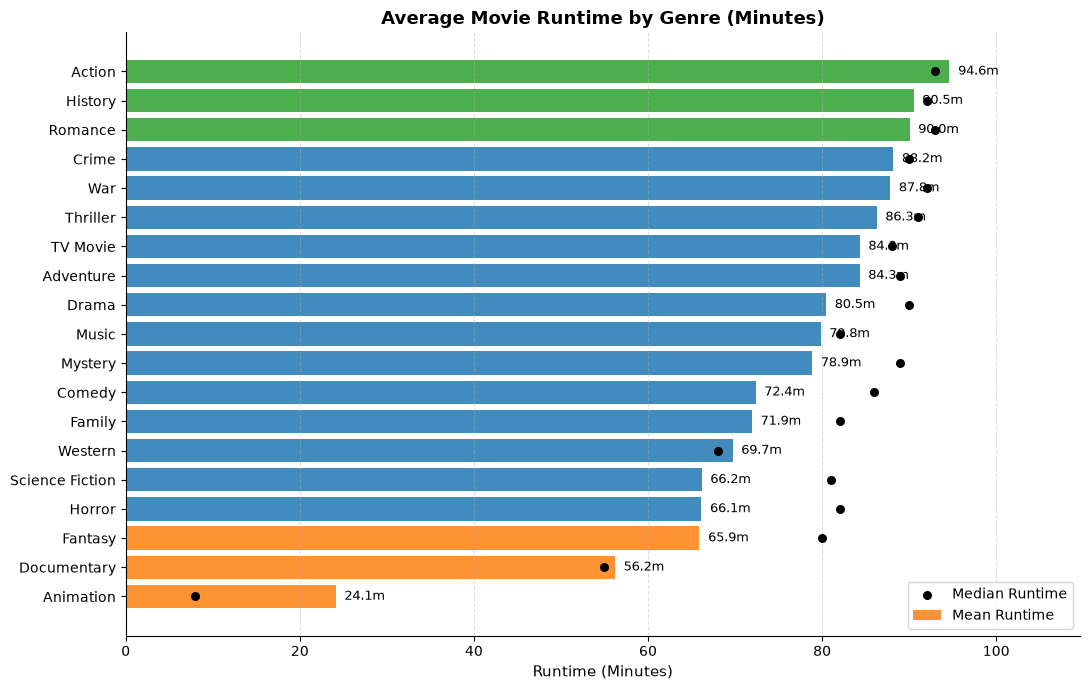

In [18]:
import matplotlib.pyplot as plt

# 1. Keep released movies with valid runtimes (1 to 300 mins) and non-null genres
runtime_df = df_base.dropna(subset=['genres', 'runtime']).copy()
runtime_df = runtime_df[(runtime_df['runtime'] > 0) & (runtime_df['runtime'] <= 300)]

# 2. Split and explode genres so every genre gets counted
runtime_df['genre'] = runtime_df['genres'].str.split(r'\s*[-,]\s*')
exploded_rt = runtime_df.explode('genre')
exploded_rt['genre'] = exploded_rt['genre'].str.strip()
exploded_rt = exploded_rt[exploded_rt['genre'] != '']

# 3. Group by genre and calculate mean, median, and count (keep genres with >= 500 movies)
genre_rt_stats = (
    exploded_rt.groupby('genre')
    .agg(
        movie_count=('id', 'count'),
        mean_runtime=('runtime', 'mean'),
        median_runtime=('runtime', 'median')
    )
)
genre_rt_stats = genre_rt_stats[genre_rt_stats['movie_count'] >= 500].sort_values('mean_runtime')

# Print top 3 shortest and top 3 longest genres
print("Shortest 3 Genres (Mean Runtime):")
print(genre_rt_stats[['mean_runtime', 'median_runtime', 'movie_count']].head(3).round(1))
print("\nLongest 3 Genres (Mean Runtime):")
print(genre_rt_stats[['mean_runtime', 'median_runtime', 'movie_count']].tail(3).round(1))

# 4. Plot horizontal bar chart of Mean Runtime with Median markers
fig, ax = plt.subplots(figsize=(11, 7))

# Color shortest 3 in orange, longest 3 in green, rest in steel blue
colors = ['#ff7f0e'] * 3 + ['#1f77b4'] * (len(genre_rt_stats) - 6) + ['#2ca02c'] * 3

bars = ax.barh(genre_rt_stats.index, genre_rt_stats['mean_runtime'], color=colors, alpha=0.85, label='Mean Runtime')
ax.scatter(genre_rt_stats['median_runtime'], genre_rt_stats.index, color='black', zorder=3, s=30, label='Median Runtime')

# Add exact minute labels at the end of each bar
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}m", va='center', fontsize=9)

ax.set_title('Average Movie Runtime by Genre (Minutes)', fontsize=13, fontweight='bold')
ax.set_xlabel('Runtime (Minutes)', fontsize=11)
ax.set_xlim(0, genre_rt_stats['mean_runtime'].max() + 15)
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.4)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Runtime by Genre
- Animation and Horror tend to be shorter
- Drama, History, and War films tend to run longer
- The gap between mean and median is largest in Documentary (a few very long films pull the average up)

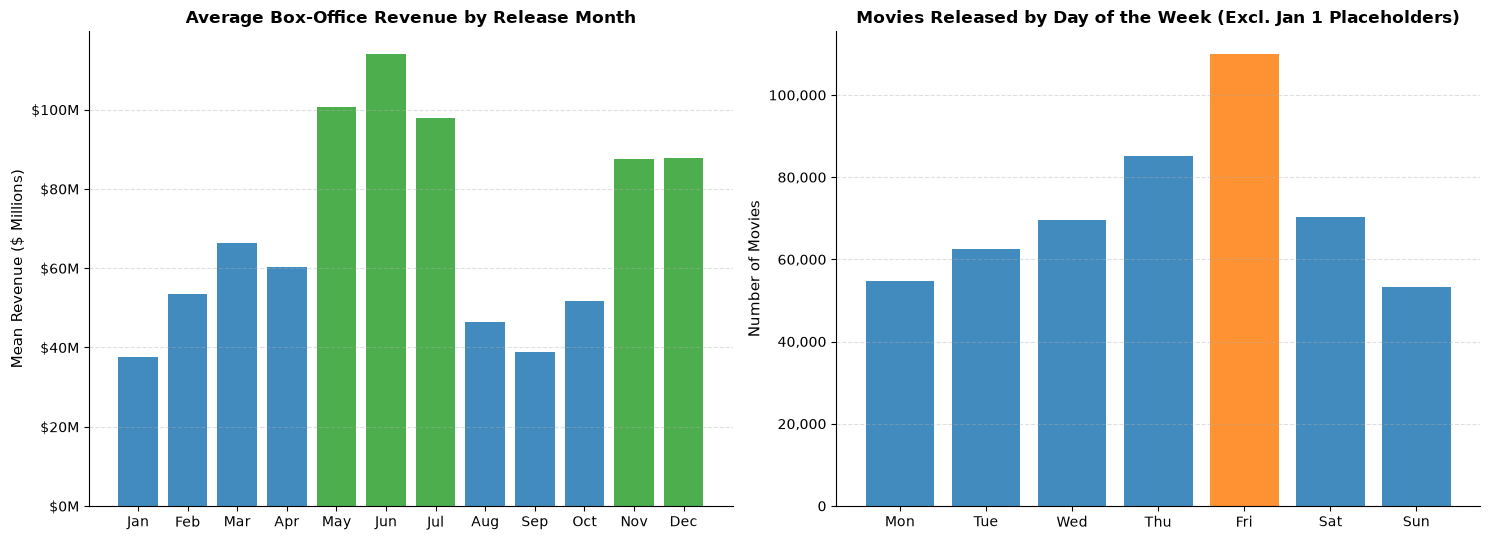

In [19]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- 1. MONTHLY BOX-OFFICE SEASONALITY (df_money) ---
money_dates = df_money.dropna(subset=['release_date']).copy()
money_dates['month'] = money_dates['release_date'].dt.month
money_dates['rev_millions'] = money_dates['revenue'] / 1e6

monthly_stats = (
    money_dates.groupby('month')
    .agg(
        movie_count=('id', 'count'),
        mean_rev=('rev_millions', 'mean'),
        median_rev=('rev_millions', 'median')
    )
)

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# --- 2. RELEASE DAY OF THE WEEK (df_base, excluding Jan 1 placeholder dates) ---
base_dates = df_base.dropna(subset=['release_date']).copy()
# Filter out Jan 1 placeholder dates often used when only release year is known
real_dates = base_dates[~((base_dates['release_date'].dt.month == 1) & (base_dates['release_date'].dt.day == 1))].copy()
real_dates['day_name'] = real_dates['release_date'].dt.day_name()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = real_dates['day_name'].value_counts().reindex(day_order)

# --- 3. PLOT SIDE-BY-SIDE IN MATPLOTLIB ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Left Panel: Mean Box-Office Revenue by Month ($ Millions)
# Highlight Summer (May-Jul) and Holiday (Nov-Dec) in green
bar_colors = ['#1f77b4', '#1f77b4', '#1f77b4', '#1f77b4',
              '#2ca02c', '#2ca02c', '#2ca02c', '#1f77b4',
              '#1f77b4', '#1f77b4', '#2ca02c', '#2ca02c']

ax1.bar(month_names, monthly_stats['mean_rev'], color=bar_colors, alpha=0.85)
ax1.set_title('Average Box-Office Revenue by Release Month', fontsize=12, fontweight='bold')
ax1.set_ylabel('Mean Revenue ($ Millions)', fontsize=11)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}M'))
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Right Panel: Total Movies Released by Day of the Week
day_colors = ['#ff7f0e' if d == 'Friday' else '#1f77b4' for d in day_order]
ax2.bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], day_counts.values, color=day_colors, alpha=0.85)
ax2.set_title('Movies Released by Day of the Week (Excl. Jan 1 Placeholders)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Number of Movies', fontsize=11)
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax2.grid(axis='y', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Release Timing Matters
Summer (May–Jul) and Holiday (Nov–Dec) releases earn significantly more on average.
Friday releases dominate because weekend box-office performance determines a film's commercial fate.

Correlation (Runtime vs. Rating, 60–240 mins): 0.309

Rating by Runtime Tier:
                         mean  median  count
runtime_tier                                
60–90m\n(Short Feature)  6.32     6.3   2604
90–120m\n(Standard)      6.43     6.4   9780
120–150m\n(Extended)     6.96     7.0   2245
150–180m\n(Epic)         7.25     7.2    321
180–240m\n(Marathon)     7.50     7.5    105


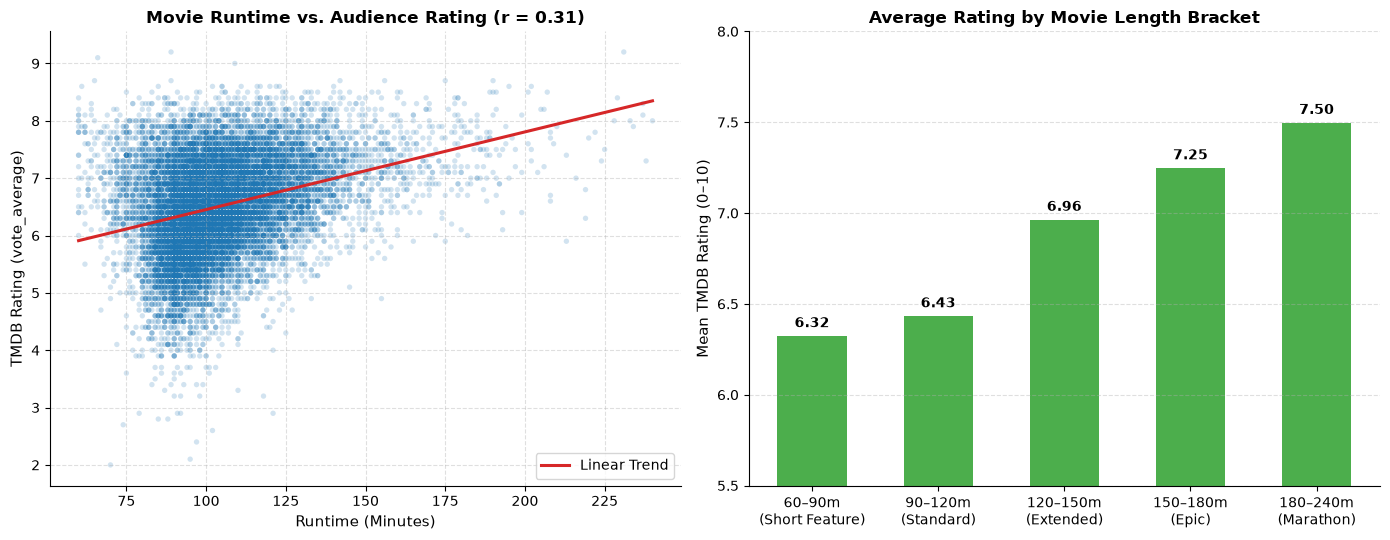

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Filter df_rated to valid feature-length runtimes (60 to 240 mins)
rt_rating = df_rated[(df_rated['runtime'] >= 60) & (df_rated['runtime'] <= 240)].copy()

# Calculate exact Pearson correlation
r_rt = rt_rating['runtime'].corr(rt_rating['vote_average'])
print(f"Correlation (Runtime vs. Rating, 60–240 mins): {r_rt:.3f}")

# 2. Group into 30-minute runtime brackets to see the exact step-up
bins = [60, 90, 120, 150, 180, 240]
labels = ['60–90m\n(Short Feature)', '90–120m\n(Standard)', '120–150m\n(Extended)', '150–180m\n(Epic)', '180–240m\n(Marathon)']
rt_rating['runtime_tier'] = pd.cut(rt_rating['runtime'], bins=bins, labels=labels, right=False)

tier_ratings = rt_rating.groupby('runtime_tier', observed=False)['vote_average'].agg(['mean', 'median', 'count'])
print("\nRating by Runtime Tier:")
print(tier_ratings.round(2))

# 3. Plot Side-by-Side in Matplotlib
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: Scatter Plot + Linear Trend Line
ax1.scatter(rt_rating['runtime'], rt_rating['vote_average'], alpha=0.2, color='#1f77b4', edgecolors='none', s=15)

# Add best-fit trend line
m, b = np.polyfit(rt_rating['runtime'], rt_rating['vote_average'], 1)
x_vals = np.linspace(60, 240, 100)
ax1.plot(x_vals, m * x_vals + b, color='#d62728', linewidth=2.2, label='Linear Trend')

ax1.set_title(f'Movie Runtime vs. Audience Rating (r = {r_rt:.2f})', fontsize=12, fontweight='bold')
ax1.set_xlabel('Runtime (Minutes)', fontsize=11)
ax1.set_ylabel('TMDB Rating (vote_average)', fontsize=11)
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.4)

# Right Panel: Mean Rating Across Runtime Brackets
bars = ax2.bar(tier_ratings.index, tier_ratings['mean'], color='#2ca02c', width=0.55, alpha=0.85)
ax2.set_title('Average Rating by Movie Length Bracket', fontsize=12, fontweight='bold')
ax2.set_ylabel('Mean TMDB Rating (0–10)', fontsize=11)
ax2.set_ylim(5.5, 8.0)
ax2.grid(axis='y', linestyle='--', alpha=0.4)

for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.05, f"{h:.2f}", ha='center', fontweight='bold', fontsize=10)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Do Longer Movies Rate Better?
If the trend line slopes upward, longer films tend to rate higher — possibly because:
- Epic films attract dedicated audiences who rate them highly
- Studios invest more in long films (better scripts, production value)
- Short films may include low-budget content that drags the average down

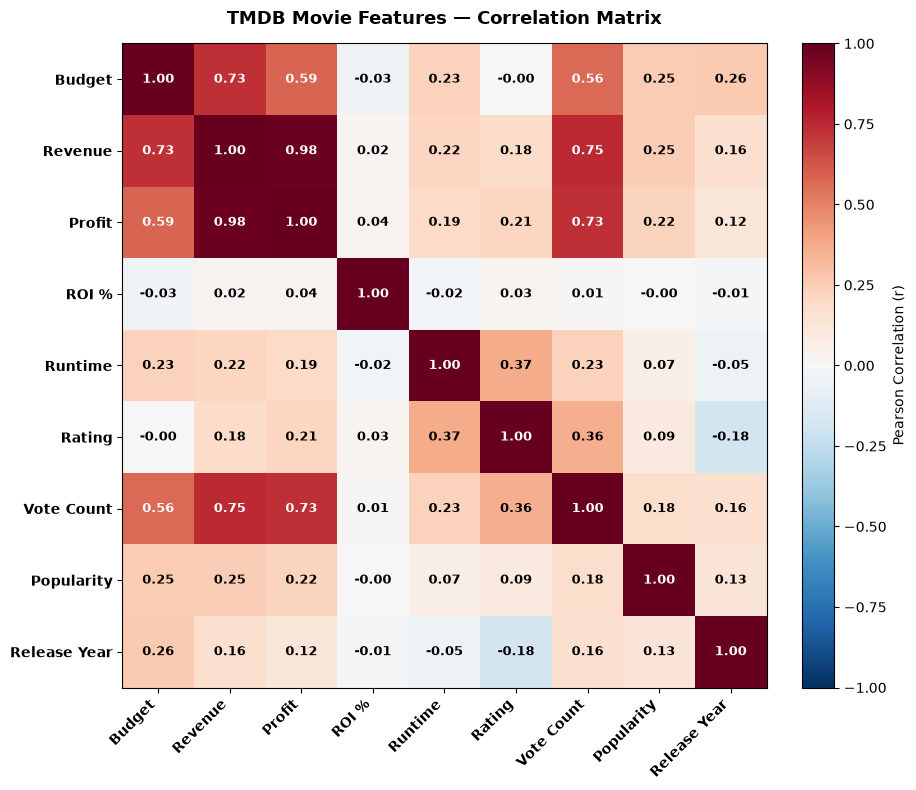

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Build a clean analytical slice combining valid financials, ratings, and runtime
corr_df = df_money[
    (df_money['vote_count'] >= 100) &
    (df_money['runtime'] > 0) &
    (df_money['runtime'] <= 300)
].copy()

# Add derived profit & ROI columns
corr_df['profit'] = corr_df['revenue'] - corr_df['budget']
corr_df['roi_pct'] = (corr_df['profit'] / corr_df['budget']) * 100

# Select key numerical columns and give them clean display labels
cols = ['budget', 'revenue', 'profit', 'roi_pct', 'runtime',
        'vote_average', 'vote_count', 'popularity', 'release_year']
labels = ['Budget', 'Revenue', 'Profit', 'ROI %', 'Runtime',
          'Rating', 'Vote Count', 'Popularity', 'Release Year']

corr_matrix = corr_df[cols].corr()

# 2. Plot Correlation Heatmap in Pure Matplotlib
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1)

# Configure axis ticks and labels
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10, fontweight='bold')
ax.set_yticklabels(labels, fontsize=10, fontweight='bold')

# Write the exact correlation number inside every square
for i in range(len(labels)):
    for j in range(len(labels)):
        val = corr_matrix.iloc[i, j]
        # Use white text on dark blue/red cells, black text on light cells
        text_color = 'white' if abs(val) > 0.55 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color=text_color, fontsize=9.5, fontweight='bold')

# Add colorbar and title
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Pearson Correlation (r)', fontsize=10)
ax.set_title('TMDB Movie Features — Correlation Matrix', fontsize=13, fontweight='bold', pad=14)

plt.tight_layout()
plt.show()


### Finding: Correlation Matrix — What to Look For

| Pair | Expected Finding |
|---|---|
| Budget ↔ Revenue | Moderate positive — more spend, more earn |
| Budget ↔ Rating | Near zero — money can't buy critical love |
| Revenue ↔ Popularity | Strong positive — popular films earn more |
| Runtime ↔ Rating | Slight positive — longer films rated slightly higher |
| ROI ↔ Budget | Slight negative — massive budgets are harder to recoup |

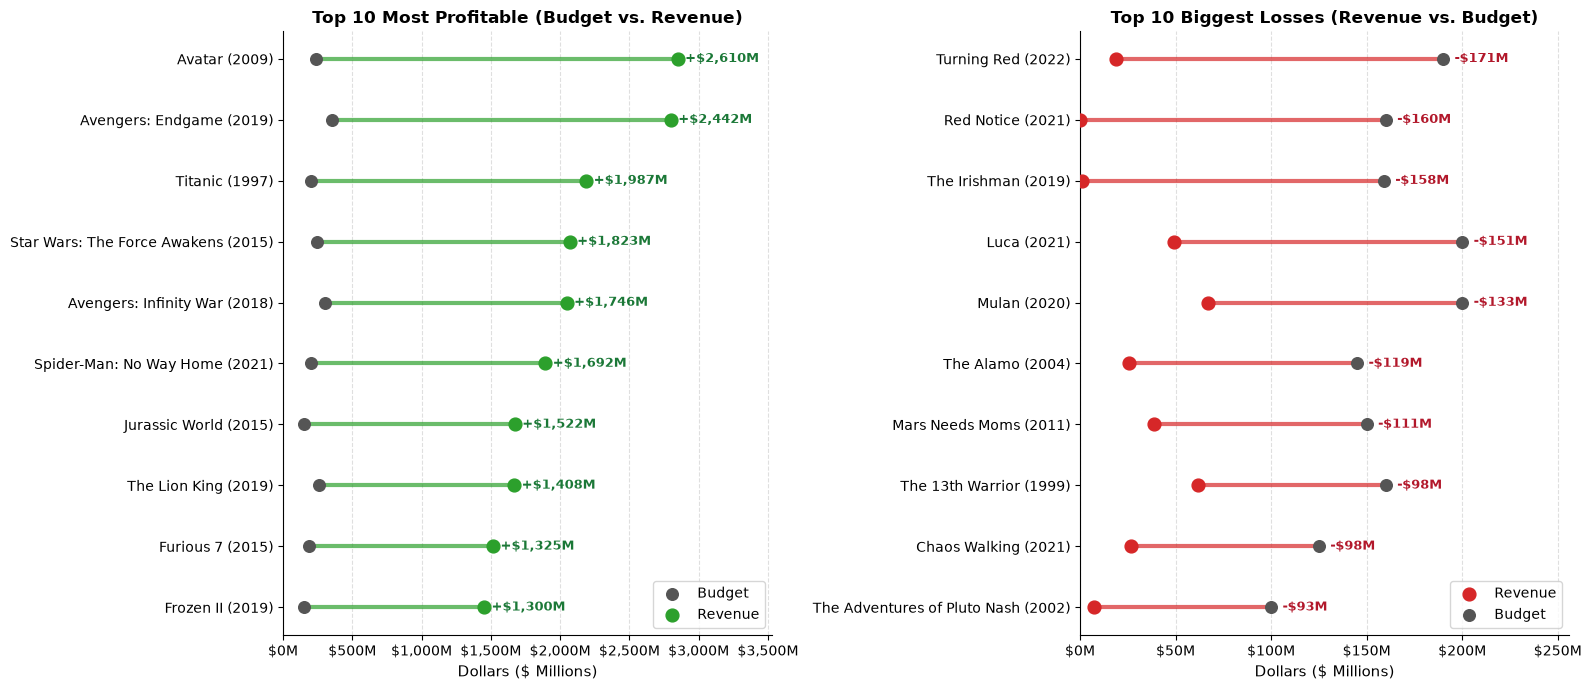

In [23]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Prepare Top 10 Winners and Top 10 Losses
real_money = df_money[df_money['vote_count'] >= 50].copy()
real_money['budget_m'] = real_money['budget'] / 1e6
real_money['revenue_m'] = real_money['revenue'] / 1e6
real_money['profit_m'] = real_money['revenue_m'] - real_money['budget_m']

# Sort ascending so #1 appears at the very top of each panel
winners = real_money.nlargest(10, 'profit_m').sort_values('profit_m', ascending=True).copy()
losers = real_money.nsmallest(10, 'profit_m').sort_values('profit_m', ascending=False).copy()

for df_sub in (winners, losers):
    df_sub['label'] = df_sub['title'] + ' (' + df_sub['release_year'].fillna(0).astype(int).astype(str) + ')'

# 2. Build Side-by-Side Dumbbell Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# --- LEFT PANEL: TOP 10 MOST PROFITABLE (Budget -> Revenue) ---
y1 = range(len(winners))
ax1.hlines(y=y1, xmin=winners['budget_m'], xmax=winners['revenue_m'], color='#2ca02c', linewidth=3, alpha=0.7)
ax1.scatter(winners['budget_m'], y1, color='#555555', s=70, zorder=3, label='Budget')
ax1.scatter(winners['revenue_m'], y1, color='#2ca02c', s=85, zorder=4, label='Revenue')

for idx, (_, row) in enumerate(winners.iterrows()):
    ax1.text(row['revenue_m'] + 55, idx, f"+${row['profit_m']:,.0f}M",
             va='center', ha='left', fontsize=9, fontweight='bold', color='#1b7837')

ax1.set_yticks(y1)
ax1.set_yticklabels(winners['label'], fontsize=10)
ax1.set_xlim(0, winners['revenue_m'].max() * 1.24)
ax1.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}M'))
ax1.set_title('Top 10 Most Profitable (Budget vs. Revenue)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Dollars ($ Millions)', fontsize=11)
ax1.legend(loc='lower right')
ax1.grid(axis='x', linestyle='--', alpha=0.4)

# --- RIGHT PANEL: TOP 10 BIGGEST LOSSES (Revenue <- Budget) ---
y2 = range(len(losers))
ax2.hlines(y=y2, xmin=losers['revenue_m'], xmax=losers['budget_m'], color='#d62728', linewidth=3, alpha=0.7)
ax2.scatter(losers['revenue_m'], y2, color='#d62728', s=85, zorder=4, label='Revenue')
ax2.scatter(losers['budget_m'], y2, color='#555555', s=70, zorder=3, label='Budget')

for idx, (_, row) in enumerate(losers.iterrows()):
    ax2.text(row['budget_m'] + 6, idx, f"-${abs(row['profit_m']):,.0f}M",
             va='center', ha='left', fontsize=9, fontweight='bold', color='#b2182b')

ax2.set_yticks(y2)
ax2.set_yticklabels(losers['label'], fontsize=10)
ax2.set_xlim(0, losers['budget_m'].max() * 1.28)
ax2.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}M'))
ax2.set_title('Top 10 Biggest Losses (Revenue vs. Budget)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Dollars ($ Millions)', fontsize=11)
ax2.legend(loc='lower right')
ax2.grid(axis='x', linestyle='--', alpha=0.4)

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Biggest Winners & Losers
- The most profitable films are typically franchise sequels or animated films — low relative budget, massive audience
- The biggest losses tend to be ambitious high-budget originals that underperformed — expensive gambles that didn't pay off

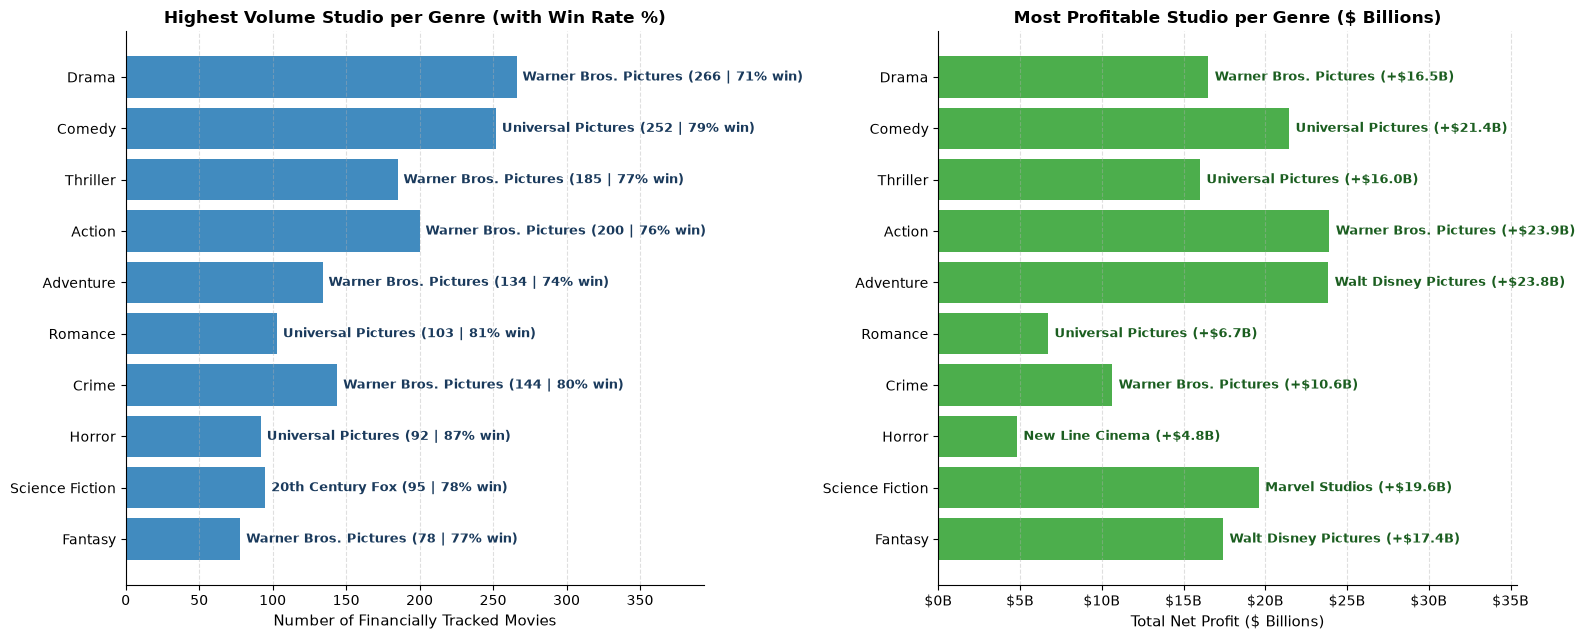

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Start with financially tracked movies that have both genres and studios
gs_df = df_money.dropna(subset=['genres', 'production_companies']).copy()
gs_df['profit_b'] = (gs_df['revenue'] - gs_df['budget']) / 1e9
gs_df['is_profitable'] = gs_df['revenue'] > gs_df['budget']

# 2. Split & explode both columns (fast on df_money since it's ~10k–15k rows)
gs_df['genre'] = gs_df['genres'].str.split(r'\s*[-,]\s*')
gs_df['studio'] = gs_df['production_companies'].str.split('-')

exploded = gs_df.explode('genre').explode('studio')
exploded['genre'] = exploded['genre'].str.strip()
exploded['studio'] = exploded['studio'].str.strip()
exploded = exploded[(exploded['genre'] != '') & (exploded['studio'] != '')]

# 3. Focus on the Top 10 largest genres in df_money
top_10_genres = exploded['genre'].value_counts().head(10).index.tolist()
sub = exploded[exploded['genre'].isin(top_10_genres)]

# Group by (genre, studio) to measure volume, total profit, and win rate
stats = (
    sub.groupby(['genre', 'studio'])
    .agg(
        movie_count=('id', 'count'),
        total_profit_b=('profit_b', 'sum'),
        win_rate=('is_profitable', lambda s: s.mean() * 100)
    )
    .reset_index()
)

# Find the #1 Volume Leader and #1 Profit Leader for each of the 10 genres
volume_leaders = (
    stats.sort_values(['movie_count', 'total_profit_b'], ascending=False)
    .drop_duplicates('genre')
    .set_index('genre')
    .reindex(top_10_genres)[::-1]  # Reverse so #1 genre is at the top
)

profit_leaders = (
    stats.sort_values('total_profit_b', ascending=False)
    .drop_duplicates('genre')
    .set_index('genre')
    .reindex(volume_leaders.index)
)

# 4. Plot Side-by-Side Comparison in Matplotlib
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# Left Panel: Most Prolific Studio per Genre + Win Rate %
bars1 = ax1.barh(volume_leaders.index, volume_leaders['movie_count'], color='#1f77b4', alpha=0.85)
ax1.set_title('Highest Volume Studio per Genre (with Win Rate %)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Financially Tracked Movies', fontsize=11)
ax1.set_xlim(0, volume_leaders['movie_count'].max() * 1.48)
ax1.grid(axis='x', linestyle='--', alpha=0.4)

for bar, (_, row) in zip(bars1, volume_leaders.iterrows()):
    w = bar.get_width()
    ax1.text(w + 4, bar.get_y() + bar.get_height()/2,
             f"{row['studio']} ({int(w)} | {row['win_rate']:.0f}% win)",
             va='center', fontsize=9, fontweight='bold', color='#1a3a5c')

# Right Panel: Highest Total Net Profit Studio per Genre ($ Billions)
bars2 = ax2.barh(profit_leaders.index, profit_leaders['total_profit_b'], color='#2ca02c', alpha=0.85)
ax2.set_title('Most Profitable Studio per Genre ($ Billions)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Total Net Profit ($ Billions)', fontsize=11)
ax2.set_xlim(0, profit_leaders['total_profit_b'].max() * 1.48)
ax2.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}B'))
ax2.grid(axis='x', linestyle='--', alpha=0.4)

for bar, (_, row) in zip(bars2, profit_leaders.iterrows()):
    w = bar.get_width()
    ax2.text(w + 0.4, bar.get_y() + bar.get_height()/2,
             f"{row['studio']} (+${w:.1f}B)",
             va='center', fontsize=9, fontweight='bold', color='#1b5e20')

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



###  Finding: Genre Ownership by Studio
Each major studio dominates specific genres — Disney/Marvel owns Action/Adventure, Universal owns Horror, etc.
But the highest-volume studio in a genre is not always the highest-profit one.
Win rate % shows which studio converts production into profit most consistently.